# 05 – Risk

Tests the portfolio thesis and quantifies risk, using the backtest of the current weights from notebook 04.

1. **Diversification between the blocks**: correlation between pies and between block A (Growth & Quality) and block B (Macro thesis), full period, sub-periods and rolling.
2. **Cross-link 6.6**: do both blocks move in the same direction when the real interest rate changes?
3. **VaR and Expected Shortfall**: historical, parametric (normal) and Monte Carlo (normal and Student-t), at 95% and 99%, over 1 day and 1 month, plus a VaR backtest.
4. **Risk contribution per pie** versus capital weight.
5. **Stress tests**: Covid crash 2020, rate shock 2022, and a hypothetical Taiwan shock (cross-link 6.2).
6. **Currency risk**: listing versus economic currency.

**Choices**: weekly returns (Friday close) for correlation, regressions and risk contribution, because daily returns of exchanges that close at different times understate co-movement; daily returns for VaR. Real rate: US 10-year TIPS yield (FRED `DFII10`).

**Caveat**: all history before 31-10-2026 is a backtest of today's selection (hindsight), with ~91–93% data coverage in 2020 and 2022 (the rest redistributed within the pie) and documented proxies.

## Setup

In [1]:
import sqlite3
from pathlib import Path
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
PROCESSED_DIR = Path("../data/processed")
DB_PATH = PROCESSED_DIR / "portfolio.db"
FRED_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DFII10"

TRADING_DAYS = 252
WEEKS = 52
MONTH_DAYS = 21
CONFIDENCE = [0.95, 0.99]
RECENT_DAYS = 2 * TRADING_DAYS
N_SIMULATIONS = 20_000
SEED = 42

BLOCKS = {
    "A": ["Kwaliteit", "Thematisch", "AI Boom"],
    "B": ["Energie", "Mijnbouw", "Multipolaire Wereldorde"],
}
SUBPERIODS = {
    "2019-2021": ("2019-01-01", "2021-12-31"),
    "2022": ("2022-01-01", "2022-12-31"),
    "2023-now": ("2023-01-01", "2100-01-01"),
}
STRESS_WINDOWS = {
    "Covid crash": ("2020-02-19", "2020-03-23"),
    "Rate shock 2022": ("2022-01-03", "2022-10-12"),
}

## Load data

In [3]:
holdings = pd.read_parquet(PROCESSED_DIR / "holdings.parquet")
returns_total = pd.read_parquet(PROCESSED_DIR / "returns_total_eur.parquet")
backtest = pd.read_parquet(PROCESSED_DIR / "backtest_returns.parquet")
pie_daily = pd.read_parquet(PROCESSED_DIR / "pie_returns.parquet").dropna()

pie_weights = holdings.groupby("pie")["weight_in_portfolio"].sum()
portfolio_daily = backtest["Portfolio (monthly rebalanced)"].dropna()
benchmark_daily = backtest["Main benchmark (monthly)"].dropna()

block_daily = pd.DataFrame({
    block: pie_daily[pies].mul(pie_weights[pies]).sum(axis=1) / pie_weights[pies].sum()
    for block, pies in BLOCKS.items()
})
print(pie_daily.shape, block_daily.shape)
pie_weights

(2023, 6) (2023, 2)


pie
AI Boom                    0.10
Energie                    0.18
Kwaliteit                  0.27
Mijnbouw                   0.17
Multipolaire Wereldorde    0.15
Thematisch                 0.13
Name: weight_in_portfolio, dtype: float64

In [4]:
def to_weekly(daily):
    """Compound daily returns into Friday-to-Friday weekly returns."""
    return (1 + daily).resample("W-FRI").prod(min_count=1) - 1


pie_weekly = to_weekly(pie_daily).dropna()
block_weekly = to_weekly(block_daily).dropna()
portfolio_weekly = to_weekly(portfolio_daily).dropna()
pie_weekly.shape

(409, 6)

## 1. Do the blocks diversify each other?

Correlation of weekly returns. A correlation well below 1 between block A and block B supports the thesis that the blocks are complementary; the rolling view shows whether that holds in every regime, or breaks down exactly when it matters.

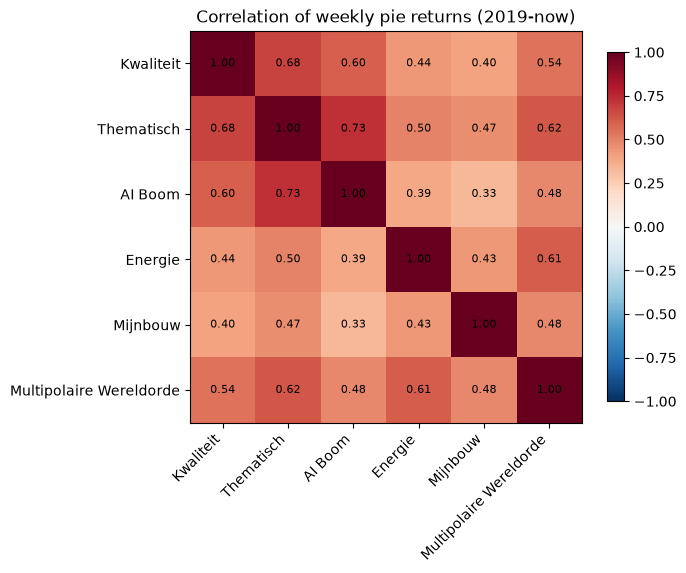

In [5]:
pie_corr = pie_weekly.corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(pie_corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(pie_corr)), pie_corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(pie_corr)), pie_corr.index)
for i in range(len(pie_corr)):
    for j in range(len(pie_corr)):
        ax.text(j, i, f"{pie_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation of weekly pie returns (2019-now)")
plt.tight_layout()
plt.show()

In [6]:
block_corr = {"full period": block_weekly["A"].corr(block_weekly["B"])}
for label, (start, end) in SUBPERIODS.items():
    window = block_weekly.loc[start:end]
    block_corr[label] = window["A"].corr(window["B"])

pd.Series(block_corr, name="corr(A, B)").round(3)

full period    0.616
2019-2021      0.766
2022           0.450
2023-now       0.531
Name: corr(A, B), dtype: float64

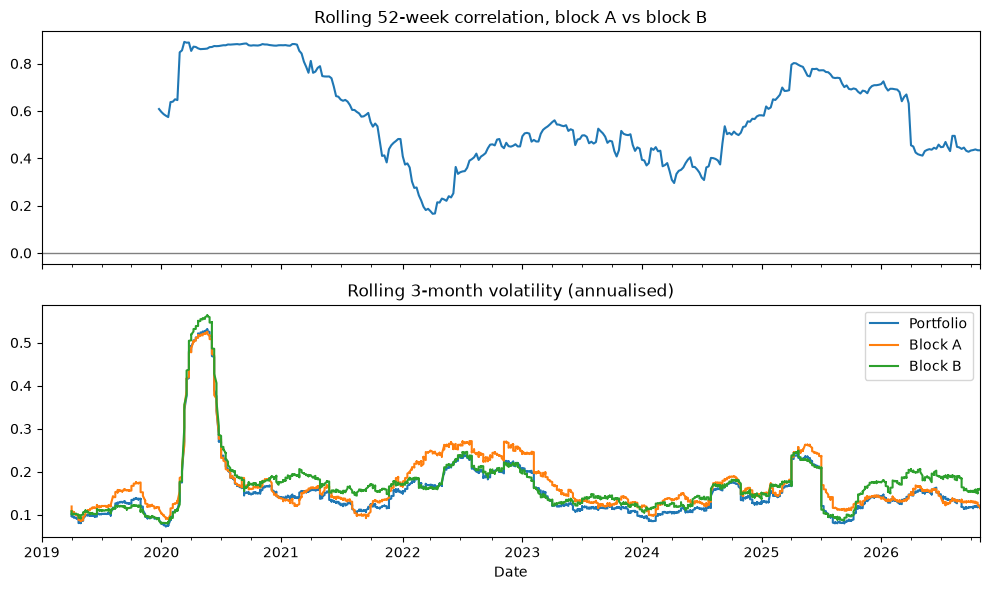

In [7]:
rolling_corr = block_weekly["A"].rolling(52).corr(block_weekly["B"])
rolling_vol = pd.concat({
    "Portfolio": portfolio_daily,
    "Block A": block_daily["A"],
    "Block B": block_daily["B"],
}, axis=1).rolling(63).std() * np.sqrt(TRADING_DAYS)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
rolling_corr.plot(ax=axes[0], title="Rolling 52-week correlation, block A vs block B")
axes[0].axhline(0, color="grey", linewidth=1)
rolling_vol.plot(ax=axes[1], title="Rolling 3-month volatility (annualised)")
plt.tight_layout()
plt.show()

## 2. Cross-link 6.6: the real interest rate

Weekly change in the US 10-year real yield (TIPS) in percentage points. For each block and pie we estimate the sensitivity of the weekly EUR return to that change, first on its own and then controlling for the equity market (MSCI World), so that the real-rate effect is not just the market effect. The thesis says the real rate is the one driver that moves **both** blocks in the **same** direction: both coefficients should then have the same sign. Note: returns are in EUR and the real yield is a USD rate, so part of the effect runs through EUR/USD. Standard errors are plain OLS (no correction for heteroskedasticity or autocorrelation).

Real yield from 2003-01-02 to 2026-10-30, last 2.60%


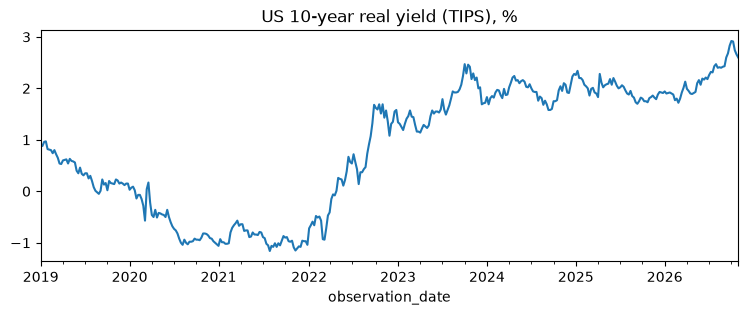

In [8]:
fred = pd.read_csv(FRED_URL, na_values=".")
fred = fred.set_index(pd.to_datetime(fred.iloc[:, 0]))["DFII10"].astype(float)
real_yield_weekly = fred.resample("W-FRI").last()
d_real = real_yield_weekly.diff().rename("d_real_yield")
market_weekly = to_weekly(returns_total["IWDA"]).rename("market")

print(f"Real yield from {fred.index.min().date()} to {fred.index.max().date()}, last {fred.dropna().iloc[-1]:.2f}%")
real_yield_weekly.loc["2019":].plot(figsize=(9, 3), title="US 10-year real yield (TIPS), %")
plt.show()

In [9]:
def ols(y, X):
    """OLS with intercept: coefficients, standard errors, t-stats and R-squared."""
    data = pd.concat([y, X], axis=1, sort=True).dropna()
    yv = data.iloc[:, 0].to_numpy()
    Xv = np.column_stack([np.ones(len(data)), data.iloc[:, 1:].to_numpy()])
    coef, *_ = np.linalg.lstsq(Xv, yv, rcond=None)
    resid = yv - Xv @ coef
    dof = len(yv) - Xv.shape[1]
    se = np.sqrt(np.diag(resid @ resid / dof * np.linalg.inv(Xv.T @ Xv)))
    names = ["const"] + list(X.columns)
    out = pd.DataFrame({"coef": coef, "se": se, "t": coef / se}, index=names)
    out.attrs["r2"] = 1 - resid.var() / yv.var()
    out.attrs["n"] = len(yv)
    return out

In [10]:
targets = pd.concat([block_weekly.add_prefix("Block "), pie_weekly], axis=1)
rows = {}
for name in targets.columns:
    simple = ols(targets[name], d_real.to_frame())
    controlled = ols(targets[name], pd.concat([d_real, market_weekly], axis=1))
    rows[name] = {
        "per +10bp (simple)": simple.loc["d_real_yield", "coef"] * 0.1,
        "t (simple)": simple.loc["d_real_yield", "t"],
        "per +10bp (market-controlled)": controlled.loc["d_real_yield", "coef"] * 0.1,
        "t (controlled)": controlled.loc["d_real_yield", "t"],
        "market beta": controlled.loc["market", "coef"],
        "n_weeks": simple.attrs["n"],
    }

real_rate_table = pd.DataFrame(rows).T
real_rate_table.round(4)

,per +10bp (simple),t (simple),per +10bp (market-controlled),t (controlled),market beta,n_weeks
Block A,-0.0060,-5.3689,-0.0017,-3.1462,1.0661,409.0
Block B,-0.0061,-5.3610,-0.0026,-3.1415,0.8475,409.0
Kwaliteit,-0.0070,-6.7625,-0.0034,-5.2616,0.8818,409.0
Thematisch,-0.0058,-3.9725,-0.0005,-0.5555,1.3075,409.0
AI Boom,-0.0036,-2.1930,0.0015,1.2232,1.2499,409.0
Energie,-0.0036,-2.6099,0.0003,0.2650,0.9400,409.0
Mijnbouw,-0.0117,-6.4840,-0.0083,-4.9677,0.8413,409.0
Multipolaire Wereldorde,-0.0027,-2.8626,0.0003,0.4840,0.7436,409.0


Read the coefficients as: the average weekly EUR return of the block or pie when the US real yield rises by 10 basis points. A |t| above roughly 2 means the effect is statistically distinguishable from zero.

## 3. Value-at-Risk and Expected Shortfall

Loss figures are shown as positive percentages of portfolio value. Two estimation windows: the full period since 2019 (including the Covid crash) and the most recent two years.

- **Historical**: the empirical quantile of returns; 1-month uses overlapping 21-day returns, which are not independent, so treat it as indicative.
- **Parametric (normal)**: mean and standard deviation, scaled to 1 month with the square-root-of-time rule (assumes independent returns).
- **Monte Carlo**: joint simulation of the six pies (weights fixed at target) from a multivariate normal and a multivariate Student-t with the same covariance; the degrees of freedom follow from the excess kurtosis of the portfolio.

In [11]:
Z = NormalDist()


def historical_var_es(r, level):
    """Historical VaR and ES (positive numbers = losses)."""
    cutoff = r.quantile(1 - level)
    return -cutoff, -r[r <= cutoff].mean()


def normal_var_es(mu, sigma, level):
    """Parametric VaR and ES under a normal distribution."""
    z = Z.inv_cdf(1 - level)
    var = -(mu + z * sigma)
    es = -(mu - sigma * Z.pdf(z) / (1 - level))
    return var, es


def simulate_portfolio(pie_returns, weights, n_sims, horizon, dist, nu=None, seed=SEED):
    """Simulated 1-day and horizon-day portfolio returns from a joint pie model."""
    rng = np.random.default_rng(seed)
    mean = pie_returns.mean().to_numpy()
    cov = pie_returns.cov().to_numpy()
    w = weights[pie_returns.columns].to_numpy()
    if dist == "normal":
        shocks = rng.multivariate_normal(np.zeros(len(mean)), cov, size=(n_sims, horizon))
    else:
        scaled_cov = cov * (nu - 2) / nu
        normal = rng.multivariate_normal(np.zeros(len(mean)), scaled_cov, size=(n_sims, horizon))
        chi = rng.chisquare(nu, size=(n_sims, horizon, 1))
        shocks = normal * np.sqrt(nu / chi)
    daily = (mean + shocks) @ w
    return pd.Series(daily[:, 0]), pd.Series(np.prod(1 + daily, axis=1) - 1)

In [12]:
windows = {"full period": portfolio_daily, "last 2 years": portfolio_daily.iloc[-RECENT_DAYS:]}
var_rows = []
for window_name, r in windows.items():
    pies = pie_daily.loc[r.index.min():r.index.max()]
    monthly_overlapping = (1 + r).rolling(MONTH_DAYS).apply(np.prod, raw=True).dropna() - 1
    excess_kurtosis = r.kurt()
    nu = float(np.clip(6 / max(excess_kurtosis, 0.01) + 4, 3, 30))
    sims = {
        "Monte Carlo (normal)": simulate_portfolio(pies, pie_weights, N_SIMULATIONS, MONTH_DAYS, "normal"),
        f"Monte Carlo (t, nu={nu:.1f})": simulate_portfolio(pies, pie_weights, N_SIMULATIONS, MONTH_DAYS, "t", nu),
    }
    for level in CONFIDENCE:
        results = {
            "Historical": (historical_var_es(r, level), historical_var_es(monthly_overlapping, level)),
            "Parametric (normal)": (
                normal_var_es(r.mean(), r.std(), level),
                normal_var_es(r.mean() * MONTH_DAYS, r.std() * np.sqrt(MONTH_DAYS), level),
            ),
        }
        for method, (one_day, one_month) in sims.items():
            results[method] = (historical_var_es(one_day, level), historical_var_es(one_month, level))
        for method, ((var_1d, es_1d), (var_1m, es_1m)) in results.items():
            var_rows.append({
                "window": window_name, "confidence": level, "method": method,
                "VaR 1d": var_1d, "ES 1d": es_1d, "VaR 1m": var_1m, "ES 1m": es_1m,
            })

var_table = pd.DataFrame(var_rows)
(var_table.set_index(["window", "confidence", "method"]) * 100).round(2)

VaR 1d  ES 1d  VaR 1m  ES 1m
window       confidence method                                               
full period  0.95       Historical                 1.56   2.56    5.82  11.19
                        Parametric (normal)        1.69   2.13    6.39   8.45
                        Monte Carlo (normal)       1.67   2.12    6.22   8.14
                        Monte Carlo (t, nu=4.5)    1.55   2.36    6.29   8.46
             0.99       Historical                 2.89   4.72   12.98  23.44
                        Parametric (normal)        2.42   2.78    9.75  11.42
                        Monte Carlo (normal)       2.41   2.77    9.29  10.84
                        Monte Carlo (t, nu=4.5)    2.77   3.79    9.65  11.79
last 2 years 0.95       Historical                 1.34   2.12    6.55   8.48
                        Parametric (normal)        1.45   1.83    5.56   7.32
                        Monte Carlo (normal)       1.44   1.83    5.44   7.09
                        Monte Carlo (t, nu=5.0)    1.35   1.95    5.38   7.17
             0.99       Historical                 2.02   3.80   10.17  11.13
                        Parametric (normal)        2.08   2.39    8.44   9.87
                        Monte Carlo (normal)       2.08   2.37    8.20   9.48
                        Monte Carlo (t, nu=5.0)    2.31   3.02    8.30   9.79

**VaR backtest.** Does a 99% one-day VaR actually hold? Each day the VaR is estimated on the previous 250 days only (out of sample), and we count how often the next day's loss is larger. Expected: 1% of days. The Kupiec test compares the observed with the expected exceedance rate; a statistic above 3.84 rejects the model at 5% significance. This is the logic behind the Basel traffic-light approach.

In [13]:
def kupiec(exceedances, n, p):
    """Kupiec proportion-of-failures likelihood ratio."""
    x = exceedances
    if x == 0:
        return -2 * n * np.log(1 - p)
    phat = x / n
    return -2 * ((n - x) * np.log(1 - p) + x * np.log(p) - (n - x) * np.log(1 - phat) - x * np.log(phat))


level = 0.99
rolling_hist = -portfolio_daily.rolling(250).quantile(1 - level).shift(1)
rolling_mu = portfolio_daily.rolling(250).mean().shift(1)
rolling_sd = portfolio_daily.rolling(250).std().shift(1)
rolling_norm = -(rolling_mu + Z.inv_cdf(1 - level) * rolling_sd)

backtest_rows = {}
for name, var_series in {"Historical (250d)": rolling_hist, "Normal (250d)": rolling_norm}.items():
    both = pd.concat([portfolio_daily, var_series], axis=1).dropna()
    hits = int((both.iloc[:, 0] < -both.iloc[:, 1]).sum())
    n = len(both)
    backtest_rows[name] = {"days": n, "exceedances": hits, "rate": hits / n, "expected": n * (1 - level), "kupiec_LR": kupiec(hits, n, 1 - level)}

pd.DataFrame(backtest_rows).T.round(4)

,days,exceedances,rate,expected,kupiec_LR
Historical (250d),1773.0,28.0,0.0158,17.73,5.1092
Normal (250d),1773.0,41.0,0.0231,17.73,22.5116


## 4. Risk contribution per pie

Euler decomposition of portfolio volatility (weekly returns): the contribution of pie *i* is its weight times the covariance of the pie with the portfolio, divided by portfolio volatility. Contributions add up to 100%. A pie whose share of risk exceeds its share of capital is a risk concentration.

In [14]:
def risk_contribution(returns, weights):
    """Percentage contribution of each column to portfolio volatility."""
    w = weights[returns.columns]
    cov = returns.cov()
    port_var = w @ cov @ w
    contribution = w * (cov @ w) / port_var
    return contribution


rc_rows = {}
for label, (start, end) in {"full period": ("2019-01-01", "2100-01-01"), **SUBPERIODS}.items():
    rc_rows[label] = risk_contribution(pie_weekly.loc[start:end], pie_weights)

risk_contrib = pd.DataFrame(rc_rows)
risk_contrib.insert(0, "capital weight", pie_weights)
block_of = {pie: block for block, pies in BLOCKS.items() for pie in pies}
print((risk_contrib.groupby(block_of).sum() * 100).round(1))
(risk_contrib * 100).round(1)

   capital weight  full period  2019-2021  2022  2023-now
A            50.0         49.7       46.3  56.8      50.6
B            50.0         50.3       53.7  43.2      49.4


,capital weight,full period,2019-2021,2022,2023-now
Kwaliteit,27.0,22.8,22.9,27.8,19.9
Thematisch,13.0,15.5,14.2,15.8,16.8
AI Boom,10.0,11.5,9.2,13.1,13.9
Energie,18.0,17.2,20.6,16.6,12.9
Mijnbouw,17.0,22.5,20.4,19.5,27.2
Multipolaire Wereldorde,15.0,10.6,12.6,7.2,9.4


## 5. Stress tests

**Historical**: cumulative return over the stress window (peak to trough of global equities), for the portfolio, the blocks, the pies and the main benchmark. Coverage shows the share of today's weight that had data at the start of the window; the rest was redistributed within its pie.

In [15]:
started = returns_total[holdings["ticker"]].notna().cummax()
weight_by_ticker = holdings.set_index("ticker")["weight_in_portfolio"]

stress_rows = {}
for name, (start, end) in STRESS_WINDOWS.items():
    window = slice(pd.Timestamp(start) + pd.Timedelta(days=1), end)
    cumulative = lambda r: (1 + r.loc[window]).prod() - 1
    row = {"Portfolio": cumulative(portfolio_daily), "Main benchmark": cumulative(benchmark_daily)}
    row.update({f"Block {b}": cumulative(block_daily[b]) for b in BLOCKS})
    row.update({pie: cumulative(pie_daily[pie]) for pie in pie_daily.columns})
    row["coverage at start"] = (started.loc[:start].iloc[-1] * weight_by_ticker).sum()
    stress_rows[f"{name} ({start} to {end})"] = row

stress_table = pd.DataFrame(stress_rows)
(stress_table * 100).round(1)

,Covid crash (2020-02-19 to 2020-03-23),Rate shock 2022 (2022-01-03 to 2022-10-12)
Portfolio,-35.3,-7.4
Main benchmark,-28.6,1.9
Block A,-32.3,-24.5
Block B,-38.1,12.6
Kwaliteit,-31.2,-18.6
Thematisch,-35.5,-31.9
AI Boom,-31.3,-32.3
Energie,-43.7,45.5
Mijnbouw,-32.5,-11.8
Multipolaire Wereldorde,-38.3,6.4


**Hypothetical Taiwan shock (cross-link 6.2).** An instantaneous shock to today's portfolio. **The shocks below are assumptions to be reviewed and justified by the portfolio owner**; they are placeholders, not forecasts. Positions not listed get the default shock of their pie.

In [16]:
TAIWAN_SHOCK = {
    "TSM": -0.50,
    "NVDA": -0.30, "AVGO": -0.30, "ASML": -0.30, "CDNS": -0.25,
    "MSFT": -0.15, "GOOGL": -0.15, "VRT": -0.20,
    "CHN": -0.25, "VGEK": -0.20,
}
DEFAULT_SHOCK_BY_PIE = {
    "Kwaliteit": -0.10,
    "Thematisch": -0.15,
    "AI Boom": -0.20,
    "Energie": -0.05,
    "Mijnbouw": 0.00,
    "Multipolaire Wereldorde": -0.10,
}

shock = holdings[["ticker", "pie", "weight_in_portfolio"]].copy()
shock["shock"] = shock["ticker"].map(TAIWAN_SHOCK).fillna(shock["pie"].map(DEFAULT_SHOCK_BY_PIE))
shock["contribution"] = shock["weight_in_portfolio"] * shock["shock"]

taiwan_by_pie = shock.groupby("pie")["contribution"].sum()
print(f"Portfolio impact: {shock['contribution'].sum():.1%}")
print(f"Block A: {taiwan_by_pie[BLOCKS['A']].sum():.1%}, Block B: {taiwan_by_pie[BLOCKS['B']].sum():.1%}")
shock.sort_values("contribution").head(10)

Portfolio impact: -10.3%
Block A: -7.4%, Block B: -2.9%


,ticker,pie,weight_in_portfolio,shock,contribution
23,TSM,AI Boom,0.0140,-0.50,-0.007000
51,CHN,Multipolaire Wereldorde,0.0225,-0.25,-0.005625
17,LOCK,Thematisch,0.0364,-0.15,-0.005460
18,GRID,Thematisch,0.0351,-0.15,-0.005265
22,NVDA,AI Boom,0.0150,-0.30,-0.004500
19,WQTM,Thematisch,0.0286,-0.15,-0.004290
25,ASML,AI Boom,0.0130,-0.30,-0.003900
49,EPIN,Multipolaire Wereldorde,0.0375,-0.10,-0.003750
27,AVGO,AI Boom,0.0120,-0.30,-0.003600
54,VGEK,Multipolaire Wereldorde,0.0180,-0.20,-0.003600


## 6. Currency risk: listing versus economic currency

Two views. **Exposure**: the currency basket implied by the listing currency versus the economic currency split (notebook 01), and the volatility of each basket from ECB rates (only currencies with an ECB series; Other DM and EM are reported as unmodelled). **Empirical**: a regression of the portfolio's weekly EUR return on world equities in USD and on the USD itself; the USD coefficient estimates the effective USD exposure, to compare with the 44% listing and 49% economic USD share.

In [17]:
with sqlite3.connect(DB_PATH) as con:
    fx_long = pd.read_sql("SELECT date, currency, eur_rate FROM fx_ecb", con, parse_dates=["date"])
fx = fx_long.pivot(index="date", columns="currency", values="eur_rate").sort_index()
fx_returns = fx.shift(1) / fx - 1  # return of holding the foreign currency for a EUR investor
fx_weekly = to_weekly(fx_returns).dropna(how="all")

listing_exposure = holdings.groupby("listing_currency")["weight_in_portfolio"].sum()
econ_columns = {"econ_usd": "USD", "econ_eur": "EUR", "econ_gbp": "GBP", "econ_chf": "CHF", "econ_cad": "CAD", "econ_other_dm": "Other DM", "econ_em": "EM"}
economic_exposure = (holdings[list(econ_columns)].mul(holdings["weight_in_portfolio"], axis=0).sum()).rename(index=econ_columns)

exposure = pd.DataFrame({"listing": listing_exposure, "economic": economic_exposure}).fillna(0)
modelled = [c for c in exposure.index if c in fx_weekly.columns]
fx_vol = {
    view: (fx_weekly[modelled] @ exposure.loc[modelled, view]).std() * np.sqrt(WEEKS)
    for view in exposure.columns
}
print("Annualised FX volatility of the modelled basket:", {k: round(v, 4) for k, v in fx_vol.items()})
print("Unmodelled share (Other DM + EM):", exposure.loc[["Other DM", "EM"]].sum().round(4).to_dict())
exposure.round(4)

Annualised FX volatility of the modelled basket: {'listing': np.float64(0.0347), 'economic': np.float64(0.0408)}
Unmodelled share (Other DM + EM): {'listing': 0.0, 'economic': 0.2322}


,listing,economic
CAD,0.0254,0.1337
CHF,0.0459,0.0459
EM,0.0000,0.1426
EUR,0.3795,0.0826
GBP,0.1089,0.0166
Other DM,0.0000,0.0896
USD,0.4403,0.4890


In [18]:
iwda_weekly = to_weekly(returns_total["IWDA"])
usd_weekly = fx_weekly["USD"]
world_in_usd = ((1 + iwda_weekly) / (1 + usd_weekly) - 1).rename("world equity (USD)")

usd_model = ols(portfolio_weekly, pd.concat([world_in_usd, usd_weekly.rename("USD")], axis=1))
print(f"R2 = {usd_model.attrs['r2']:.3f}, n = {usd_model.attrs['n']} weeks")
usd_model.round(4)

R2 = 0.814, n = 409 weeks


,coef,se,t
const,0.0011,0.0005,2.1367
world equity (USD),0.9807,0.0234,41.8471
USD,0.6729,0.0554,12.1395


## Export

In [19]:
corr_long = pie_corr.stack().rename("correlation").reset_index()
corr_long.columns = ["pie_1", "pie_2", "correlation"]
rolling_long = pd.concat({"corr A-B (52w)": rolling_corr, **{f"vol {c} (3m)": rolling_vol[c] for c in rolling_vol}}, axis=1)
rolling_long = rolling_long.stack().dropna().rename("value").reset_index()
rolling_long.columns = ["date", "series", "value"]

tables = {
    "risk_correlation": corr_long,
    "risk_rolling": rolling_long,
    "risk_real_rate": real_rate_table.reset_index(names="series"),
    "risk_var": var_table,
    "risk_contribution": risk_contrib.reset_index(names="pie"),
    "risk_stress": stress_table.reset_index(names="series"),
    "risk_taiwan": shock,
}
with sqlite3.connect(DB_PATH) as con:
    for name, table in tables.items():
        table.to_sql(name, con, if_exists="replace", index=False)
        table.to_parquet(PROCESSED_DIR / f"{name}.parquet", index=False)
list(tables)

C:\Users\caswv\AppData\Local\Temp\ipykernel_31748\2184899237.py:3: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  rolling_long = pd.concat({"corr A-B (52w)": rolling_corr, **{f"vol {c} (3m)": rolling_vol[c] for c in rolling_vol}}, axis=1)


['risk_correlation',
 'risk_rolling',
 'risk_real_rate',
 'risk_var',
 'risk_contribution',
 'risk_stress',
 'risk_taiwan']